# DeepSense-X — Phase 3: Transformer Autoencoder
**MetroPT-3 | Google Colab CPU-friendly notebook**

Objective: train a compact Transformer Autoencoder on the same MetroPT-3 window data, calculate reconstruction errors, choose a threshold from validation data, evaluate sampled test windows, visualize results, and save the model and outputs.

Configuration mirrors Phase 2: 5,000 training windows, 2,000 validation windows, 10,000 test windows, maximum 3 epochs, batch size 128. Results are preliminary sampled event-period detection results, not proof of advance failure forecasting.

## 1. Mount Google Drive and set paths

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

BASE_DIR = Path('/content/drive/MyDrive/DeepSense_X_MetroPT3')
PROCESSED_DIR = BASE_DIR / 'processed'
ARTIFACT_DIR = BASE_DIR / 'artifacts'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

PHASE1_PATH = PROCESSED_DIR / 'metropt3_phase1_windows.npz'
print('TensorFlow:', tf.__version__)
print('Phase 1 file exists:', PHASE1_PATH.exists())
if not PHASE1_PATH.exists():
    raise FileNotFoundError(f'File not found: {PHASE1_PATH}')

Mounted at /content/drive
TensorFlow: 2.21.0
Phase 1 file exists: True


## 2. Load Phase 1 data

In [2]:
phase1 = np.load(PHASE1_PATH, allow_pickle=True)
print('Available keys:', phase1.files)

required = ['X_train', 'X_val', 'X_test', 'test_window_times', 'y_test_event']
missing = [k for k in required if k not in phase1.files]
if missing:
    raise KeyError(f'Missing keys: {missing}')

X_train = phase1['X_train'].astype('float32')
X_val = phase1['X_val'].astype('float32')
X_test = phase1['X_test'].astype('float32')
y_test = phase1['y_test_event'].astype('int32')

N_TIMESTEPS, N_FEATURES = int(X_train.shape[1]), int(X_train.shape[2])
print('Training:', X_train.shape)
print('Validation:', X_val.shape)
print('Testing:', X_test.shape)
print('Test labels:', y_test.shape)

assert X_train.ndim == 3 and X_val.shape[1:] == (N_TIMESTEPS, N_FEATURES)
assert X_test.shape[1:] == (N_TIMESTEPS, N_FEATURES)
assert len(y_test) == len(X_test)
print('Phase 1 data loaded successfully.')

Available keys: ['X_train', 'X_val', 'X_test', 'train_scores', 'val_scores', 'test_scores', 'test_window_times', 'y_test_event', 'y_test_anomaly_pred_baseline']
Training: (214791, 60, 13)
Validation: (230389, 60, 13)
Testing: (524836, 60, 13)
Test labels: (524836,)
Phase 1 data loaded successfully.


## 3. Create lightweight samples
We use the same sample sizes and fixed random seed as Phase 2 for a practical Colab CPU experiment.

In [3]:
SEED = 42
rng = np.random.default_rng(SEED)
tf.keras.utils.set_random_seed(SEED)

train_idx = np.sort(rng.choice(len(X_train), 5000, replace=False))
val_idx = np.sort(rng.choice(len(X_val), 2000, replace=False))
test_idx = np.sort(rng.choice(len(X_test), 10000, replace=False))

X_train_fit = X_train[train_idx]
X_val_fit = X_val[val_idx]
X_test_eval = X_test[test_idx]
y_test_eval = y_test[test_idx]

print('Training sample:', X_train_fit.shape)
print('Validation sample:', X_val_fit.shape)
print('Test sample:', X_test_eval.shape)
print('Event-labelled test windows:', int(y_test_eval.sum()))

Training sample: (5000, 60, 13)
Validation sample: (2000, 60, 13)
Test sample: (10000, 60, 13)
Event-labelled test windows: 516


## 4. Build a compact Transformer Autoencoder
A Dense projection maps each sensor vector to an embedding. Learnable positional embeddings represent time-step order. Multi-head self-attention learns relationships across the 60 time steps. The reconstruction head outputs the original 13 features.

In [8]:

# Clear the previous incorrect model
keras.backend.clear_session()

EMBED_DIM = 32
NUM_HEADS = 2
FF_DIM = 64
NUM_TRANSFORMER_BLOCKS = 1
DROPOUT_RATE = 0.10

# Correct positional embedding layer
class PositionEmbedding(layers.Layer):
    def __init__(self, sequence_length, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.embed_dim = embed_dim
        self.embedding = layers.Embedding(
            input_dim=sequence_length,
            output_dim=embed_dim
        )

    def call(self, inputs):
        positions = tf.range(
            start=0,
            limit=tf.shape(inputs)[1],
            delta=1
        )
        position_embeddings = self.embedding(positions)

        # Preserve the batch dimension
        return inputs + tf.expand_dims(position_embeddings, axis=0)


def transformer_encoder_block(x, embed_dim, num_heads, ff_dim, dropout_rate):

    attention_output = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=dropout_rate
    )(x, x)

    x = layers.Add()([x, attention_output])
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    ff_output = layers.Dense(ff_dim, activation='relu')(x)
    ff_output = layers.Dropout(dropout_rate)(ff_output)
    ff_output = layers.Dense(embed_dim)(ff_output)

    x = layers.Add()([x, ff_output])
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    return x


# Input
inputs = keras.Input(
    shape=(N_TIMESTEPS, N_FEATURES),
    name='sensor_window'
)

# Project sensor features into embedding dimension
x = layers.Dense(EMBED_DIM, name='input_projection')(inputs)

# Add positional embeddings correctly
x = PositionEmbedding(
    N_TIMESTEPS,
    EMBED_DIM,
    name='position_embedding'
)(x)

# Transformer encoder
for block_id in range(NUM_TRANSFORMER_BLOCKS):
    x = transformer_encoder_block(
        x,
        EMBED_DIM,
        NUM_HEADS,
        FF_DIM,
        DROPOUT_RATE
    )

# Reconstruct original 13 sensor features
outputs = layers.TimeDistributed(
    layers.Dense(N_FEATURES),
    name='reconstruction'
)(x)

# Build model
transformer_autoencoder = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name='DeepSenseX_Transformer_Autoencoder'
)

transformer_autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mae'
)

transformer_autoencoder.summary()


Model: "DeepSenseX_Transformer_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sensor_window       │ (None, 60, 13)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_projection    │ (None, 60, 32)    │        448 │ sensor_window[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ position_embedding  │ (None, 60, 32)    │      1,920 │ input_projection… │
│ (PositionEmbedding) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 60, 32)    │      4,224 │ position_embeddi… │
│ (MultiHeadAttentio… │                   │            │ position_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 60, 32)    │          0 │ position_embeddi… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 60, 32)    │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 60, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 60, 64)    │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 60, 32)    │      2,080 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 60, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 60, 32)    │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reconstruction      │ (None, 60, 13)    │        429 │ layer_normalizat… │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,341 (44.30 KB)

 Trainable params: 11,341 (44.30 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
print("TensorFlow version:", tf.__version__)

print("Training input shape:", X_train_fit.shape)
print("Validation input shape:", X_val_fit.shape)

print("Model input shape:", transformer_autoencoder.input_shape)
print("Model output shape:", transformer_autoencoder.output_shape)

print("\nModel layers:")
transformer_autoencoder.summary()

TensorFlow version: 2.21.0
Training input shape: (5000, 60, 13)
Validation input shape: (2000, 60, 13)
Model input shape: (None, 60, 13)
Model output shape: (60, 60, 13)

Model layers:


Model: "DeepSenseX_Transformer_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sensor_window       │ (None, 60, 13)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_projection    │ (None, 60, 32)    │        448 │ sensor_window[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_position_embed… │ (60, 60, 32)      │          0 │ input_projection… │
│ (Add)               │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (60, 60, 32)      │      4,224 │ add_position_emb… │
│ (MultiHeadAttentio… │                   │            │ add_position_emb… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (60, 60, 32)      │          0 │ add_position_emb… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (60, 60, 32)      │         64 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (60, 60, 64)      │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (60, 60, 64)      │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (60, 60, 32)      │      2,080 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (60, 60, 32)      │          0 │ layer_normalizat… │
│                     │                   │            │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (60, 60, 32)      │         64 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reconstruction      │ (60, 60, 13)      │        429 │ layer_normalizat… │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 28,265 (110.41 KB)

 Trainable params: 9,421 (36.80 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 18,844 (73.61 KB)

In [9]:
print("Input shape:", transformer_autoencoder.input_shape)
print("Output shape:", transformer_autoencoder.output_shape)

assert transformer_autoencoder.output_shape == (None, 60, 13)

print("SUCCESS: Model dimensions are correct!")

Input shape: (None, 60, 13)
Output shape: (None, 60, 13)
SUCCESS: Model dimensions are correct!


## 5. Train the Transformer Autoencoder
Maximum 3 epochs, batch size 128. Early stopping and checkpointing preserve the best validation-loss weights.

In [10]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=2,
        restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        str(ARTIFACT_DIR / 'phase3_transformer_autoencoder_best.keras'),
        monitor='val_loss', save_best_only=True, verbose=1
    )
]

history = transformer_autoencoder.fit(
    X_train_fit, X_train_fit,
    validation_data=(X_val_fit, X_val_fit),
    epochs=3, batch_size=128, shuffle=True,
    callbacks=callbacks, verbose=1
)

Epoch 1/3
39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - loss: 0.7572
Epoch 1: val_loss improved from None to 0.65805, saving model to /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase3_transformer_autoencoder_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase3_transformer_autoencoder_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 15s 168ms/step - loss: 0.5292 - val_loss: 0.6581
Epoch 2/3
39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - loss: 0.2392
Epoch 2: val_loss improved from 0.65805 to 0.50828, saving model to /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase3_transformer_autoencoder_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase3_transformer_autoencoder_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 197ms/step - loss: 0.2152 - val_loss: 0.5083
Epoch 3/3
39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - loss: 0.1549
Epoch 3: val_loss improved from 0.50828 to 0.43085, saving model

## 6. Plot training and validation loss

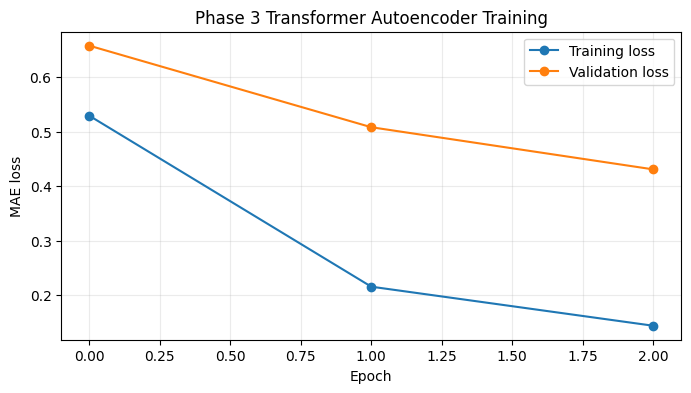

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], marker='o', label='Training loss')
plt.plot(history.history['val_loss'], marker='o', label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('MAE loss')
plt.title('Phase 3 Transformer Autoencoder Training')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 7. Calculate reconstruction errors

In [12]:
def reconstruction_errors(model, X, batch_size=128):
    reconstructed = model.predict(X, batch_size=batch_size, verbose=1)
    errors = np.mean(np.abs(X - reconstructed), axis=(1, 2))
    return errors.astype('float32')

val_errors = reconstruction_errors(transformer_autoencoder, X_val_fit)
test_errors = reconstruction_errors(transformer_autoencoder, X_test_eval)

print('Validation errors:', val_errors.shape)
print('Test errors:', test_errors.shape)
print('Validation percentiles:',
      np.percentile(val_errors, [50, 90, 95, 99, 99.5, 100]))

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step
Validation errors: (2000,)
Test errors: (10000,)
Validation percentiles: [ 0.19256902  0.57959694  1.76231391  1.96427774  5.89885058 38.80603409]


## 8. Select anomaly threshold
The 99th percentile of validation reconstruction errors is used as the cutoff. It is not a guarantee of a 1% false-positive rate on test data.

In [13]:
THRESHOLD_PERCENTILE = 99.0
anomaly_threshold = float(np.percentile(val_errors, THRESHOLD_PERCENTILE))

print('Anomaly threshold:', anomaly_threshold)
print('Validation windows above threshold:',
      int((val_errors > anomaly_threshold).sum()))
print('Validation flagged percentage:',
      f'{100 * np.mean(val_errors > anomaly_threshold):.2f}%')

Anomaly threshold: 1.964277744293213
Validation windows above threshold: 20
Validation flagged percentage: 1.00%


## 9. Predict anomalies on sampled test windows

In [14]:
test_predictions = (test_errors > anomaly_threshold).astype('int32')
print('Predicted anomalous windows:', int(test_predictions.sum()))
print('Predicted anomaly percentage:', f'{100 * test_predictions.mean():.2f}%')
print('Event-labelled sampled test windows:', int(y_test_eval.sum()))

Predicted anomalous windows: 974
Predicted anomaly percentage: 9.74%
Event-labelled sampled test windows: 516


## 10. Evaluation metrics

In [15]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score,
    confusion_matrix, classification_report
)

precision = precision_score(y_test_eval, test_predictions, zero_division=0)
recall = recall_score(y_test_eval, test_predictions, zero_division=0)
f1 = f1_score(y_test_eval, test_predictions, zero_division=0)
accuracy = accuracy_score(y_test_eval, test_predictions)
cm = confusion_matrix(y_test_eval, test_predictions, labels=[0, 1])

print(f'Precision: {precision:.4f} ({precision*100:.2f}%)')
print(f'Recall:    {recall:.4f} ({recall*100:.2f}%)')
print(f'F1-score:  {f1:.4f} ({f1*100:.2f}%)')
print(f'Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)')
print('Confusion Matrix [[TN, FP], [FN, TP]]:')
print(cm)
print(classification_report(y_test_eval, test_predictions, zero_division=0))

Precision: 0.5267 (52.67%)
Recall:    0.9942 (99.42%)
F1-score:  0.6886 (68.86%)
Accuracy:  0.9536 (95.36%)
Confusion Matrix [[TN, FP], [FN, TP]]:
[[9023  461]
 [   3  513]]
              precision    recall  f1-score   support

           0       1.00      0.95      0.97      9484
           1       0.53      0.99      0.69       516

    accuracy                           0.95     10000
   macro avg       0.76      0.97      0.83     10000
weighted avg       0.98      0.95      0.96     10000



## 11. Visualize validation and test reconstruction errors

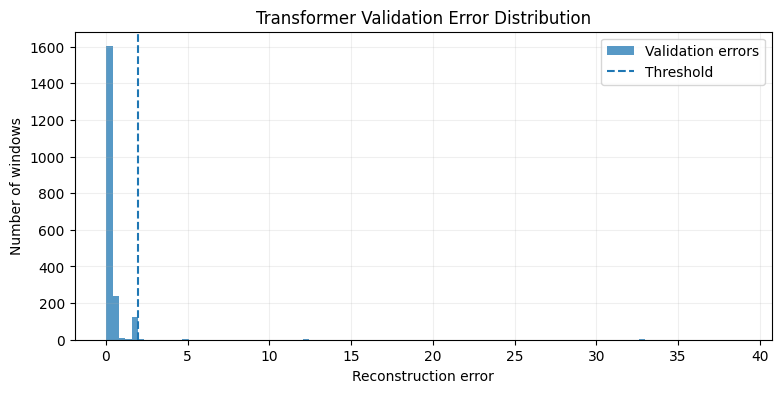

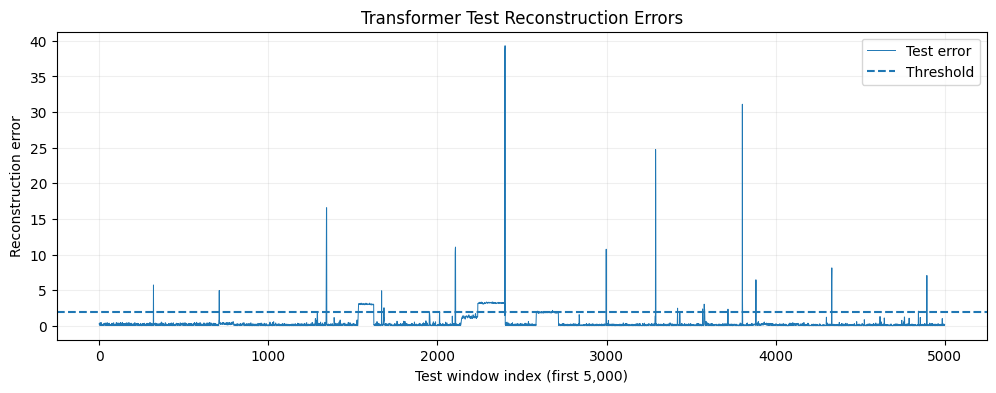

In [16]:
plt.figure(figsize=(9, 4))
plt.hist(val_errors, bins=100, alpha=0.75, label='Validation errors')
plt.axvline(anomaly_threshold, linestyle='--', label='Threshold')
plt.xlabel('Reconstruction error')
plt.ylabel('Number of windows')
plt.title('Transformer Validation Error Distribution')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(test_errors[:5000], linewidth=0.7, label='Test error')
plt.axhline(anomaly_threshold, linestyle='--', label='Threshold')
plt.xlabel('Test window index (first 5,000)')
plt.ylabel('Reconstruction error')
plt.title('Transformer Test Reconstruction Errors')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 12. Event-wise sample coverage and detection
This aligns timestamps with the sampled test indices and checks whether each known failure interval is represented in the random sample.

In [17]:
test_times_eval = pd.to_datetime(phase1['test_window_times'])[test_idx]

event_intervals = {
    'Event 1 (18 Apr 2020)': ('2020-04-18 00:00:00', '2020-04-19 00:00:00'),
    'Event 2 (29-30 May 2020)': ('2020-05-29 23:30:00', '2020-05-30 06:00:00'),
    'Event 3 (5-7 Jun 2020)': ('2020-06-05 10:00:00', '2020-06-07 14:30:00'),
}

rows = []
for name, (start, end) in event_intervals.items():
    mask = (
        (test_times_eval >= pd.Timestamp(start)) &
        (test_times_eval <= pd.Timestamp(end))
    )
    total = int(mask.sum())
    flagged = int(test_predictions[mask].sum())
    rows.append({
        'Event': name,
        'Sampled event windows': total,
        'Detected windows': flagged,
        'Detection rate (%)': round(100 * flagged / total, 2) if total else np.nan
    })

event_results = pd.DataFrame(rows)
display(event_results)

,Event,Sampled event windows,Detected windows,Detection rate (%)
0,Event 1 (18 Apr 2020),147,145,98.64
1,Event 2 (29-30 May 2020),47,46,97.87
2,Event 3 (5-7 Jun 2020),322,322,100.00


## 13. Save Phase 3 model, results and metadata

In [18]:
final_model_path = ARTIFACT_DIR / 'phase3_transformer_autoencoder_final.keras'
transformer_autoencoder.save(final_model_path)

results_path = PROCESSED_DIR / 'metropt3_phase3_transformer_results.npz'
np.savez_compressed(
    results_path,
    val_errors=val_errors,
    test_errors=test_errors,
    test_predictions=test_predictions,
    y_test_event=y_test_eval,
    test_idx=test_idx,
    threshold=np.array(anomaly_threshold, dtype='float32')
)

metadata = {
    'phase': 3,
    'model': 'Transformer Autoencoder',
    'input_shape': [int(N_TIMESTEPS), int(N_FEATURES)],
    'embedding_dimension': EMBED_DIM,
    'attention_heads': NUM_HEADS,
    'feed_forward_dimension': FF_DIM,
    'transformer_blocks': NUM_TRANSFORMER_BLOCKS,
    'training_windows_available': int(len(X_train)),
    'training_windows_used': int(len(X_train_fit)),
    'validation_windows_available': int(len(X_val)),
    'validation_windows_used': int(len(X_val_fit)),
    'test_windows_available': int(len(X_test)),
    'test_windows_used': int(len(X_test_eval)),
    'threshold_percentile': float(THRESHOLD_PERCENTILE),
    'anomaly_threshold': float(anomaly_threshold),
    'precision': float(precision),
    'recall': float(recall),
    'f1_score': float(f1),
    'accuracy': float(accuracy),
    'confusion_matrix': cm.tolist(),
    'evaluation_note': 'Preliminary sampled event-period detection, not pre-failure forecasting.'
}

metadata_path = ARTIFACT_DIR / 'phase3_transformer_metadata.json'
with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=2)

print('PHASE 3 SAVED SUCCESSFULLY!')
print('Model:', final_model_path)
print('Results:', results_path)
print('Metadata:', metadata_path)

PHASE 3 SAVED SUCCESSFULLY!
Model: /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase3_transformer_autoencoder_final.keras
Results: /content/drive/MyDrive/DeepSense_X_MetroPT3/processed/metropt3_phase3_transformer_results.npz
Metadata: /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase3_transformer_metadata.json


## 14. Verify saved files

In [19]:
for path in [final_model_path, results_path, metadata_path]:
    print(('FOUND' if path.exists() else 'MISSING'), path)

FOUND /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase3_transformer_autoencoder_final.keras
FOUND /content/drive/MyDrive/DeepSense_X_MetroPT3/processed/metropt3_phase3_transformer_results.npz
FOUND /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase3_transformer_metadata.json


## Phase 3 completion checklist
- [ ] Phase 1 data loaded
- [ ] Lightweight samples created
- [ ] Transformer Autoencoder built and trained
- [ ] Training/validation loss plotted
- [ ] Reconstruction errors and validation threshold calculated
- [ ] Sampled test metrics calculated
- [ ] Error plots reviewed
- [ ] Event-wise sample coverage checked
- [ ] Model, results and metadata saved

**Research note:** Compare Phase 3 with Phase 2 using the same sample indices, threshold policy and labels. This notebook uses the same seed and sample sizes; verify indices match if you want a strict comparison. Do not claim advance failure prediction until a separate pre-failure forecasting evaluation is implemented.